# 02 · Sensors, noise, and the gap between model and reality
**Level: Beginner** · ~10 min · *Track: Foundations*

A real asset is observed only through a handful of **noisy point sensors**. This notebook asks:

1. What does the twin actually *see*? (the observation operator $H$)
2. Can we reconstruct the whole field from sensors alone, with interpolation and no physics?
3. What happens if we run the physics model *without* data (open loop)?

From here on we use the `dtwin` package. `Heat1D` is the same heat equation as in notebook 01,
but with the **Crank-Nicolson** scheme: implicit, unconditionally stable, second-order in time.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import Heat1D
from dtwin.sensors import PointSensors, evenly_spaced_1d
viz.set_style()
rng = np.random.default_rng(42)

## 1. The "real" rod
We pretend this simulation is reality. Its parameters are **hidden** from the twin later on:
diffusivity $\alpha=0.012$ and a heater whose power changes over time.

In [2]:
TRUE_ALPHA = 0.012

def true_power(t):
    return 0.5 + 0.3 * np.sin(2 * np.pi * t / 6) + 0.4 * (t > 8)

def heater_shape(x):
    return np.exp(-((x - 0.35) / 0.05) ** 2)

real = Heat1D(nx=121, alpha=TRUE_ALPHA, dt=0.02)
x = real.x
t, U_true = real.simulate(np.zeros_like(x), 750, source=lambda x, t: true_power(t) * heater_shape(x))

## 2. Virtual sensors and the observation operator
Six thermocouples, each with Gaussian noise $\sigma=0.01$. Mathematically a sensor array is a
matrix $H$ that picks entries out of the state vector:
$$y_k = H\,u_k + v_k,\qquad v_k\sim\mathcal N(0, R),\; R=\sigma^2 I.$$

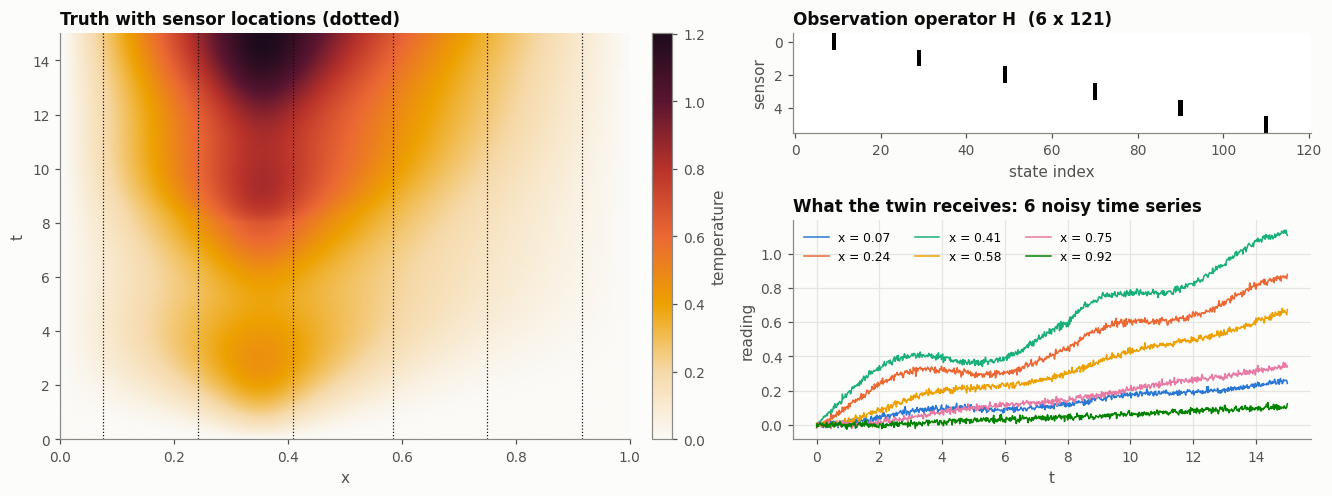

In [3]:
sens = PointSensors(evenly_spaced_1d(real.nx, 6), real.nx, noise_std=0.01)
Y = sens.observe(U_true, rng)          # (n_times, 6)
xs = x[sens.idx]

fig = plt.figure(figsize=(12, 4.4), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1.1, 1], height_ratios=[1, 2.2])
ax = fig.add_subplot(gs[:, 0])
viz.spacetime(ax, U_true, x, t, label="temperature")
for xi in xs:
    ax.axvline(xi, color=viz.INK, lw=0.8, ls=":")
ax.set_title("Truth with sensor locations (dotted)")
axH = fig.add_subplot(gs[0, 1])
axH.grid(False)
axH.imshow(sens.H, aspect="auto", cmap="Greys", interpolation="nearest")
axH.set(title="Observation operator H  (6 x 121)", xlabel="state index", ylabel="sensor")
ax = fig.add_subplot(gs[1, 1])
for i in range(sens.m):
    ax.plot(t, Y[:, i], lw=1, color=viz.SERIES[i], label=f"x = {xs[i]:.2f}")
ax.set(xlabel="t", ylabel="reading", title="What the twin receives: 6 noisy time series")
ax.legend(ncol=3, fontsize=8)
viz.save(fig, "02_sensors.png")
plt.show()

## 3. Data only: reconstruct the field by interpolation
Without physics, the simplest guess between sensors is interpolation. We assume the ends are known
($u=0$, ice baths) and compare linear and cubic-spline interpolation.

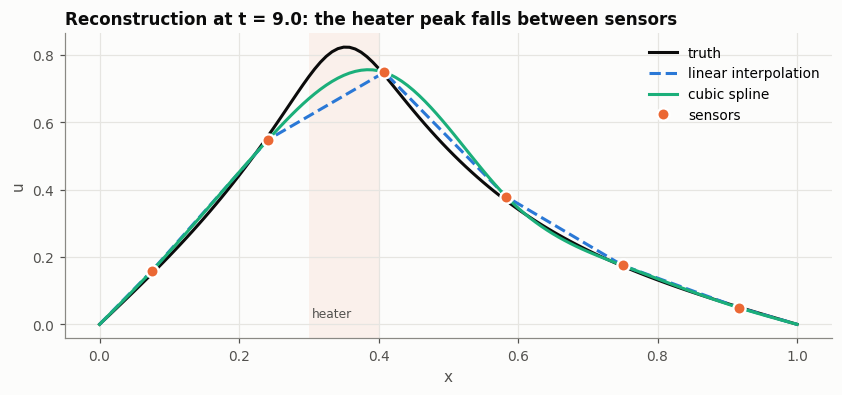

In [4]:
def interp_field(y, xs, x, kind="linear"):
    xp = np.r_[0.0, xs, 1.0]
    yp = np.r_[0.0, y, 0.0]
    return np.interp(x, xp, yp) if kind == "linear" else CubicSpline(xp, yp, bc_type="natural")(x)

k = int(9.0 / real.dt)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(x, U_true[k], color=viz.TRUTH, label="truth")
ax.plot(x, interp_field(Y[k], xs, x, "linear"), color=viz.BLUE, ls="--", label="linear interpolation")
ax.plot(x, interp_field(Y[k], xs, x, "cubic"), color=viz.AQUA, label="cubic spline")
ax.plot(xs, Y[k], "o", color=viz.DATA, ms=8, mec="white", mew=1.5, label="sensors", zorder=5)
ax.axvspan(0.3, 0.4, color=viz.ORANGE, alpha=0.08, lw=0)
ax.text(0.305, 0.02, "heater", color=viz.INK2, fontsize=8)
ax.set(xlabel="x", ylabel="u", title=f"Reconstruction at t = {t[k]:.1f}: the heater peak falls between sensors")
ax.legend()
plt.show()

Interpolation misses the peak: no sensor sits on it, and interpolation has no idea that a
heater exists. How many sensors would we need?

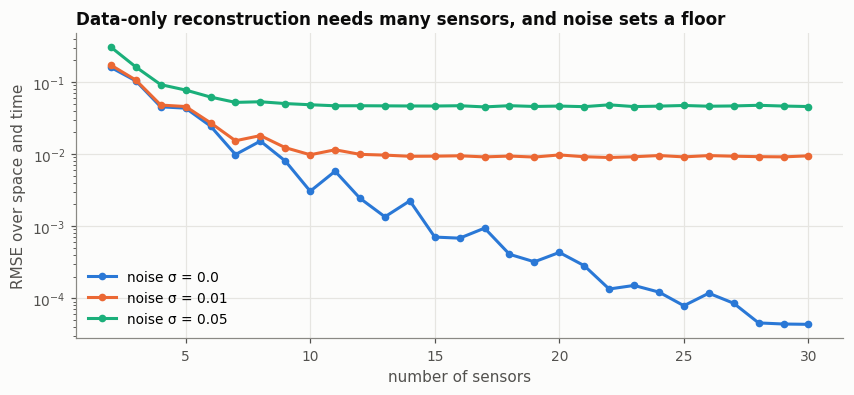

In [5]:
ms = np.arange(2, 31)
noise_levels = [0.0, 0.01, 0.05]
fig, ax = plt.subplots(figsize=(9, 3.6))
for j, sd in enumerate(noise_levels):
    err = []
    for m in ms:
        s = PointSensors(evenly_spaced_1d(real.nx, m, margin=0.03), real.nx, sd)
        Ym = s.observe(U_true[::10], rng)
        rec = np.array([interp_field(y, x[s.idx], x, "cubic") for y in Ym])
        err.append(np.sqrt(np.mean((rec - U_true[::10]) ** 2)))
    ax.semilogy(ms, err, "o-", ms=4, color=viz.SERIES[j], label=f"noise σ = {sd}")
ax.set(xlabel="number of sensors", ylabel="RMSE over space and time",
       title="Data-only reconstruction needs many sensors, and noise sets a floor")
ax.legend()
plt.show()

## 4. Physics only: the open-loop twin
Now the opposite extreme. Our twin knows the physics, but its parameters come from a datasheet,
so they are slightly wrong: $\alpha = 0.008$ instead of $0.012$, and it assumes the heater runs at
a constant 0.6. It never looks at the data.

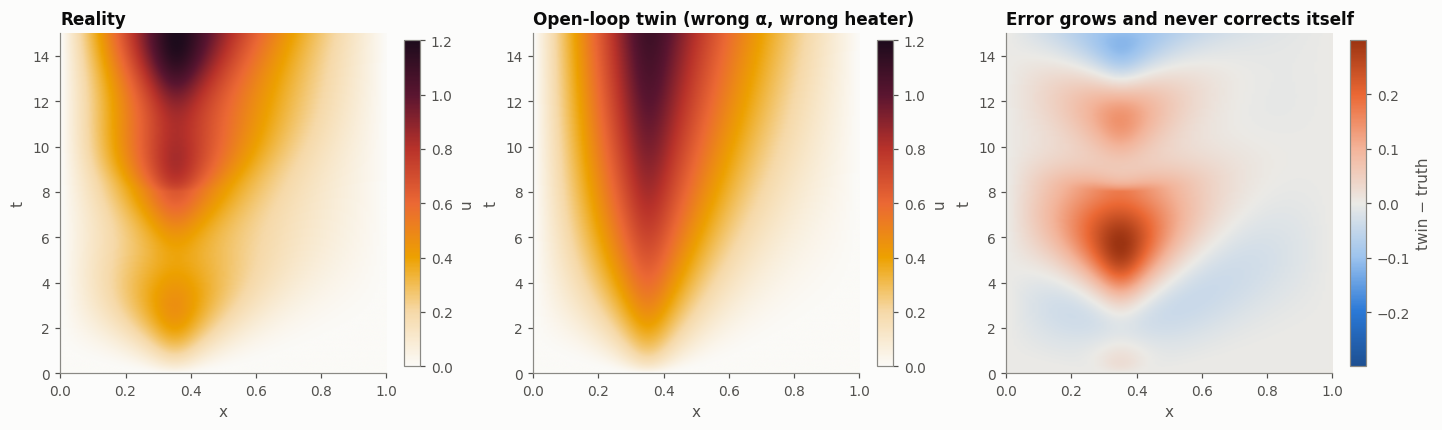

In [6]:
twin = Heat1D(nx=121, alpha=0.008, dt=0.02)
_, U_open = twin.simulate(np.zeros_like(x), 750, source=lambda x, t: 0.6 * heater_shape(x))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
vmax = max(U_true.max(), U_open.max())
viz.spacetime(axes[0], U_true, x, t, vmin=0, vmax=vmax, label="u")
axes[0].set_title("Reality")
viz.spacetime(axes[1], U_open, x, t, vmin=0, vmax=vmax, label="u")
axes[1].set_title("Open-loop twin (wrong α, wrong heater)")
err = U_open - U_true
lim = np.abs(err).max()
viz.spacetime(axes[2], err, x, t, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="twin − truth")
axes[2].set_title("Error grows and never corrects itself")
plt.show()

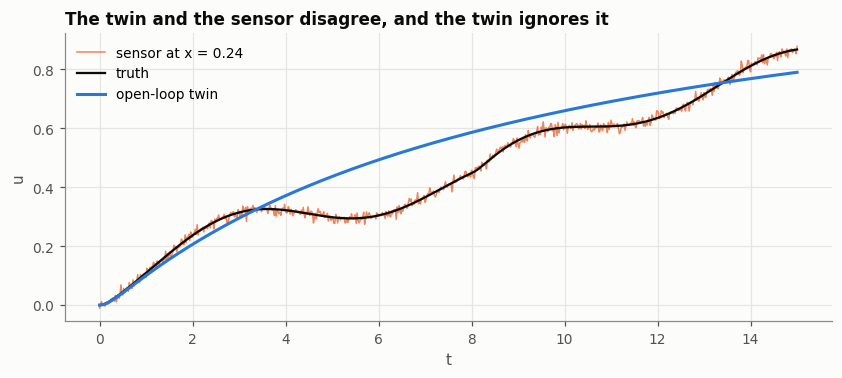

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.4))
i = 1  # the sensor closest to the heater
ax.plot(t, Y[:, i], color=viz.DATA, lw=1, alpha=0.8, label=f"sensor at x = {xs[i]:.2f}")
ax.plot(t, U_true[:, sens.idx[i]], color=viz.TRUTH, lw=1.5, label="truth")
ax.plot(t, U_open[:, sens.idx[i]], color=viz.TWIN, label="open-loop twin")
ax.set(xlabel="t", ylabel="u", title="The twin and the sensor disagree, and the twin ignores it")
ax.legend()
plt.show()

In [8]:
idx = np.arange(0, len(t), 12)
anim = viz.animate_1d(x, [U_true[idx], U_open[idx]], t[idx], labels=["reality", "open-loop twin"],
                      colors=[viz.TRUTH, viz.TWIN], styles=["-", "--"],
                      points=(xs, Y[idx]), title="Reality vs. open-loop twin")
HTML(anim.to_jshtml())

## Recap: the twin gap
| Approach | Strength | Weakness |
|---|---|---|
| **Data only** (interpolation) | always agrees with sensors | blind between sensors, no forecast |
| **Physics only** (open loop) | full field + forecast | drifts if parameters, sources or initial state are wrong |
| **Digital twin** = physics **+** data | best of both | *this is the rest of the course* |

The next notebooks close the gap in increasing order of sophistication:
* **03** calibrate the unknown parameters (offline inverse problem)
* **04** correct the state continuously with a Kalman filter (online data assimilation)

**Exercises**
1. Put a sensor exactly at the heater ($x=0.35$). How much does the interpolation error drop?
2. With noise $\sigma=0.05$, is it better to have 6 good sensors or 20 noisy ones?